# Завдання 1: LLM для аналізу тексту (персона + тональність)

Завдання моделі — з коротких повідомлень витягнути персону (людину) та визначити тональність висловлювання щодо цієї персони.

Ваша основна робота — сконструювати чіткий промпт, який змусить модель стабільно повертати строго сформатований JSON без зайвого тексту.

In [1]:
!pip install openai

In [2]:
import os
import json
from openai import OpenAI
from google.colab import userdata

# Використовуємо дешеву та швидку модель для таких завдань, наприклад, llama-3-8b-instruct або gemini-2.5-flash
# Отримуємо ключ із захищеного сховища Colab
api_key = userdata.get('OPENROUTER_API_KEY')

client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=api_key
)
MODEL = "google/gemini-2.5-flash"

# 2) 5 коротких текстів для аналізу
texts = [
    "Оксана Дрозд натхненно провела демо — команда аплодувала стоячи.",
    "Керівник відділу Андрій Король грубо порушив інструкції, через що реліз зірвано.",
    "Роман Бондаренко надіслав звіт о 14:00 і підтвердив графік зустрічей.",
    "Сьогодні Ілля Ткачук блискуче оптимізував код і заощадив 30% бюджету.",
    "Марко Савченко ігнорує повідомлення й затримує погодження — це неприйнятно.",
]

# 3) Промпт для суворого JSON-виводу
PROMPT_STUDENT = """
Ти — автоматична система аналізу тональності. Твоя єдина мета — аналізувати текст і повертати результат у форматі строгого, чистого JSON.

ПРАВИЛА:
1. Знайди в тексті ім'я та прізвище персони. Вилучи посади чи титули. Запиши у ключ "person".
2. Визнач тональність висловлювання щодо цієї персони. Запиши у ключ "tone".
3. Допустимі значення для "tone" строго обмежені: "позитивна", "нейтральна", "негативна".
4. ФОРМАТ: Повертай ТІЛЬКИ валідний JSON-об'єкт (один рядок). Жодних вступних чи завершальних слів, жодних пояснень. КАТЕГОРИЧНО ЗАБОРОНЕНО використовувати markdown-розмітку (не додавай ```json або ```).

Приклад роботи:
Вхідний текст: "Менеджер Василь Стус знову провалив дедлайн."
Вихід: {"person":"Василь Стус", "tone":"негативна"}
"""

# 4) Виклик моделі (мінімальний цикл)
for t in texts:
    resp = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "developer", "content": PROMPT_STUDENT.strip()},
            {"role": "user",
             "content": f"Проаналізуй текст і поверни ТІЛЬКИ JSON з ключами person та tone.\nТекст: <<<{t}>>>"},
        ],
        temperature=0 # Нульова температура для максимальної стабільності та детермінованості
    )
    result = resp.choices[0].message.content.strip()

    # Додаткове очищення на випадок, якщо модель все ж додасть markdown (запобіжник)
    if result.startswith("```json"):
        result = result[7:-3].strip()
    elif result.startswith("```"):
        result = result[3:-3].strip()

    try:
        json.loads(result) # перевірка, чи валідний JSON
        print(result)  # очікується чистий JSON без пояснень
    except json.JSONDecodeError:
        print(f"Помилка парсингу JSON. Відповідь моделі:\n{result}")

{"person":"Оксана Дрозд", "tone":"позитивна"}
{"person":"Андрій Король", "tone":"негативна"}
{"person":"Роман Бондаренко", "tone":"нейтральна"}
{"person":"Ілля Ткачук", "tone":"позитивна"}
{"person":"Марко Савченко", "tone":"негативна"}


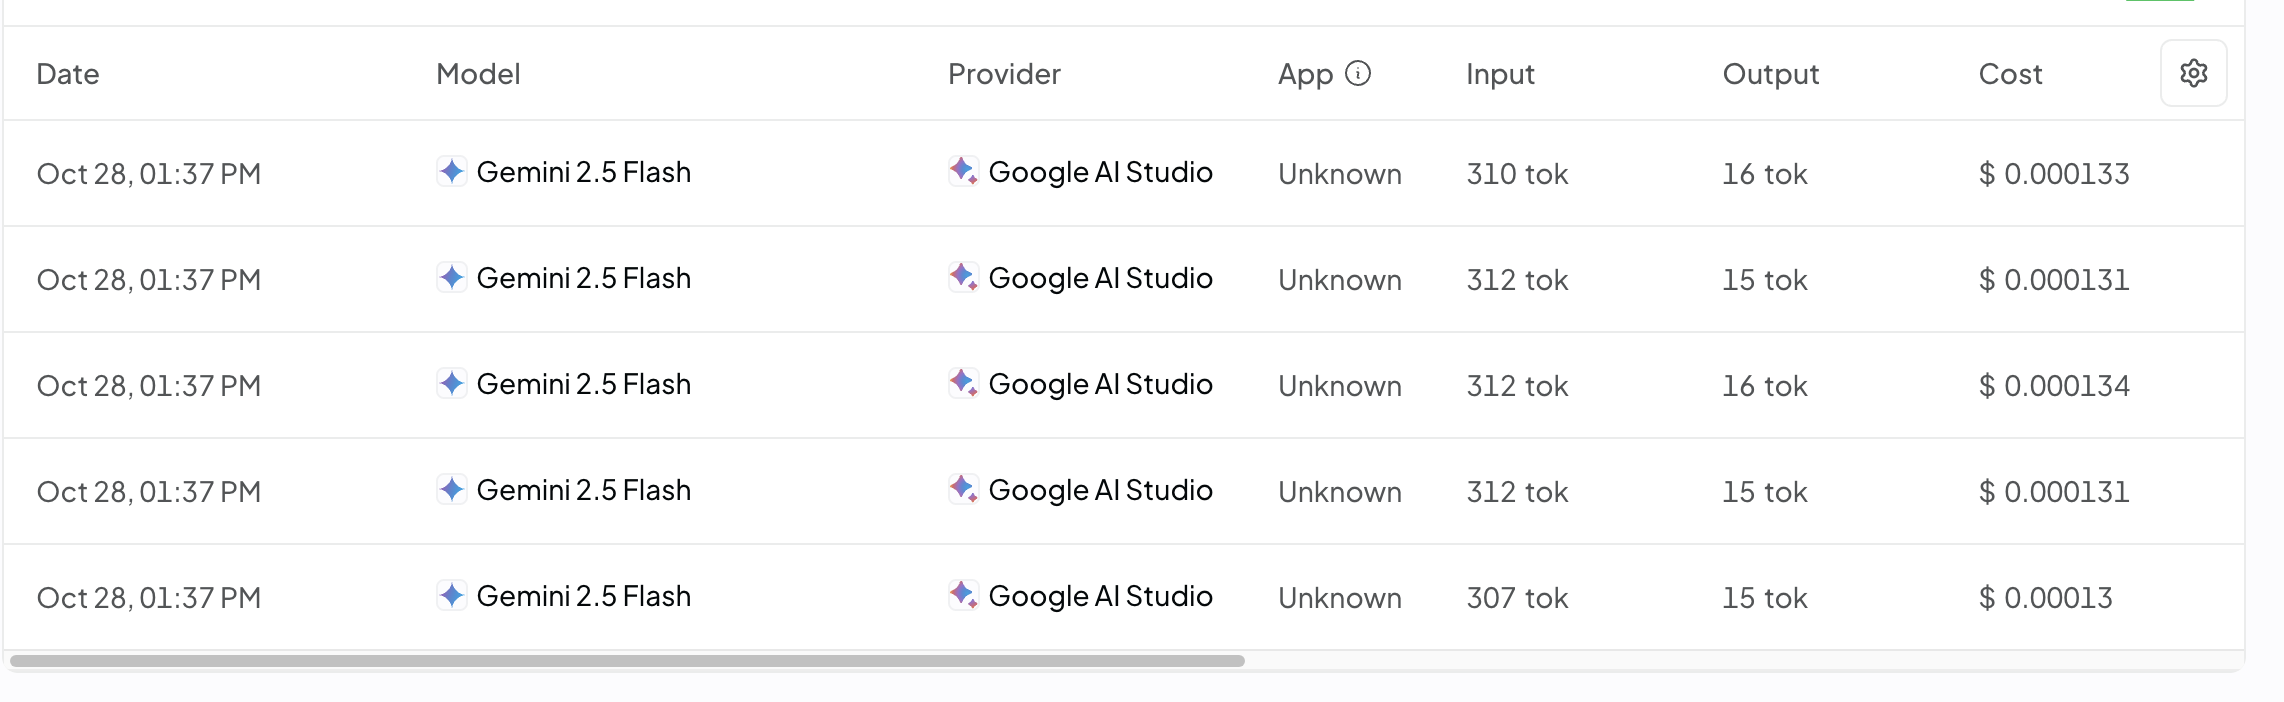

# Завдання 2: Тріаж відгуків — «продукт» + «пріоритет»

Тріаж — це процес швидкої класифікації та пріоритезації вхідних сигналів (наприклад, відгуків користувачів, баг-репортів, звернень у підтримку).


Завдання: скласти промпт, який витягує з кожного тексту назву продукту (з множини Atlas, Core, Desk) і пріоритет (високий|середній|низький).

In [3]:
import os
import json
from openai import OpenAI
from google.colab import userdata

# Отримуємо ключ із захищеного сховища Colab
api_key = userdata.get('OPENROUTER_API_KEY')

client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=api_key
)
MODEL = "google/gemini-2.5-flash"

# 5 коротких текстів для аналізу
texts = [
    "Квитанції не завантажуються в Atlas Pro з мобільного — фінвідділ стоїть.",
    "Після оновлення 3.1 у Core графіки будуються на 2 секунди довше, але працюють стабільно.",
    "Автовідповідь у Desk на свята — nice-to-have, допоможе трохи зменшити навантаження на операторів.",
    "Core падає під час імпорту CSV >100 тис. рядків — роботу заблоковано.",
    "Atlas показує старі курси валют, поки що оновлюємо вручну."
]

# Промпт для тріажу відгуків
PROMPT_STUDENT = """
Ти — автоматична система тріажу повідомлень і баг-репортів. Твоє завдання — визначити продукт і пріоритет проблеми з тексту та повернути результат строго у форматі JSON.

ПРАВИЛА ТРІАЖУ:
1. "product": Визнач назву продукту. Допустимі значення СТРОГО тільки з множини: "Atlas", "Core", "Desk".
   - Зверни увагу: якщо в тексті згадується "Atlas Pro", повертай базову назву "Atlas".
2. "priority": Визнач рівень пріоритету проблеми. Допустимі значення СТРОГО тільки з множини: "високий", "середній", "низький".
   - "високий": критичні збої, блокування роботи, зупинка бізнес-процесів, падіння системи, неактуальні критичні дані.
   - "середній": незначні затримки, сповільнення роботи при збереженні стабільності та функціональності.
   - "низький": побажання, покращення, nice-to-have фічі, незначні зручності.
   - Якщо згадується кілька чинників, обирай домінантний (найвищий) пріоритет.

3. ФОРМАТ ВІДПОВІДІ:
   - Повертай ТІЛЬКИ один валідний JSON-об'єкт вигляду: {"product": "<назва>", "priority": "<рівень>"}.
   - КАТЕГОРИЧНО ЗАБОРОНЕНО додавати будь-який вступний чи пояснювальний текст, а також markdown-позначки (```json або ```).

Приклад роботи:
Вхідний текст: "Служба Desk повністю недоступна — клієнти не можуть увійти."
Вихід: {"product":"Desk","priority":"високий"}
"""

# 4) Виклик моделі (мінімальний цикл)
for t in texts:
    resp = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "developer", "content": PROMPT_STUDENT.strip()},
            {"role": "user",
             "content": f"Проаналізуй текст і поверни ТІЛЬКИ JSON з ключами product та priority.\nТекст: <<<{t}>>>"},
        ],
        temperature=0
    )
    result = resp.choices[0].message.content.strip()

    # Додаткове очищення на випадок, якщо модель все ж додасть markdown (запобіжник)
    if result.startswith("```json"):
        result = result[7:-3].strip()
    elif result.startswith("```"):
        result = result[3:-3].strip()

    try:
        json.loads(result) # перевірка, чи валідний JSON
        print(result)  # очікується чистий JSON без пояснень
    except json.JSONDecodeError:
        print(f"Помилка парсингу JSON. Відповідь моделі:\n{result}")

{"product":"Atlas","priority":"високий"}
{"product":"Core","priority":"середній"}
{"product":"Desk","priority":"низький"}
{"product":"Core","priority":"високий"}
{"product":"Atlas","priority":"високий"}


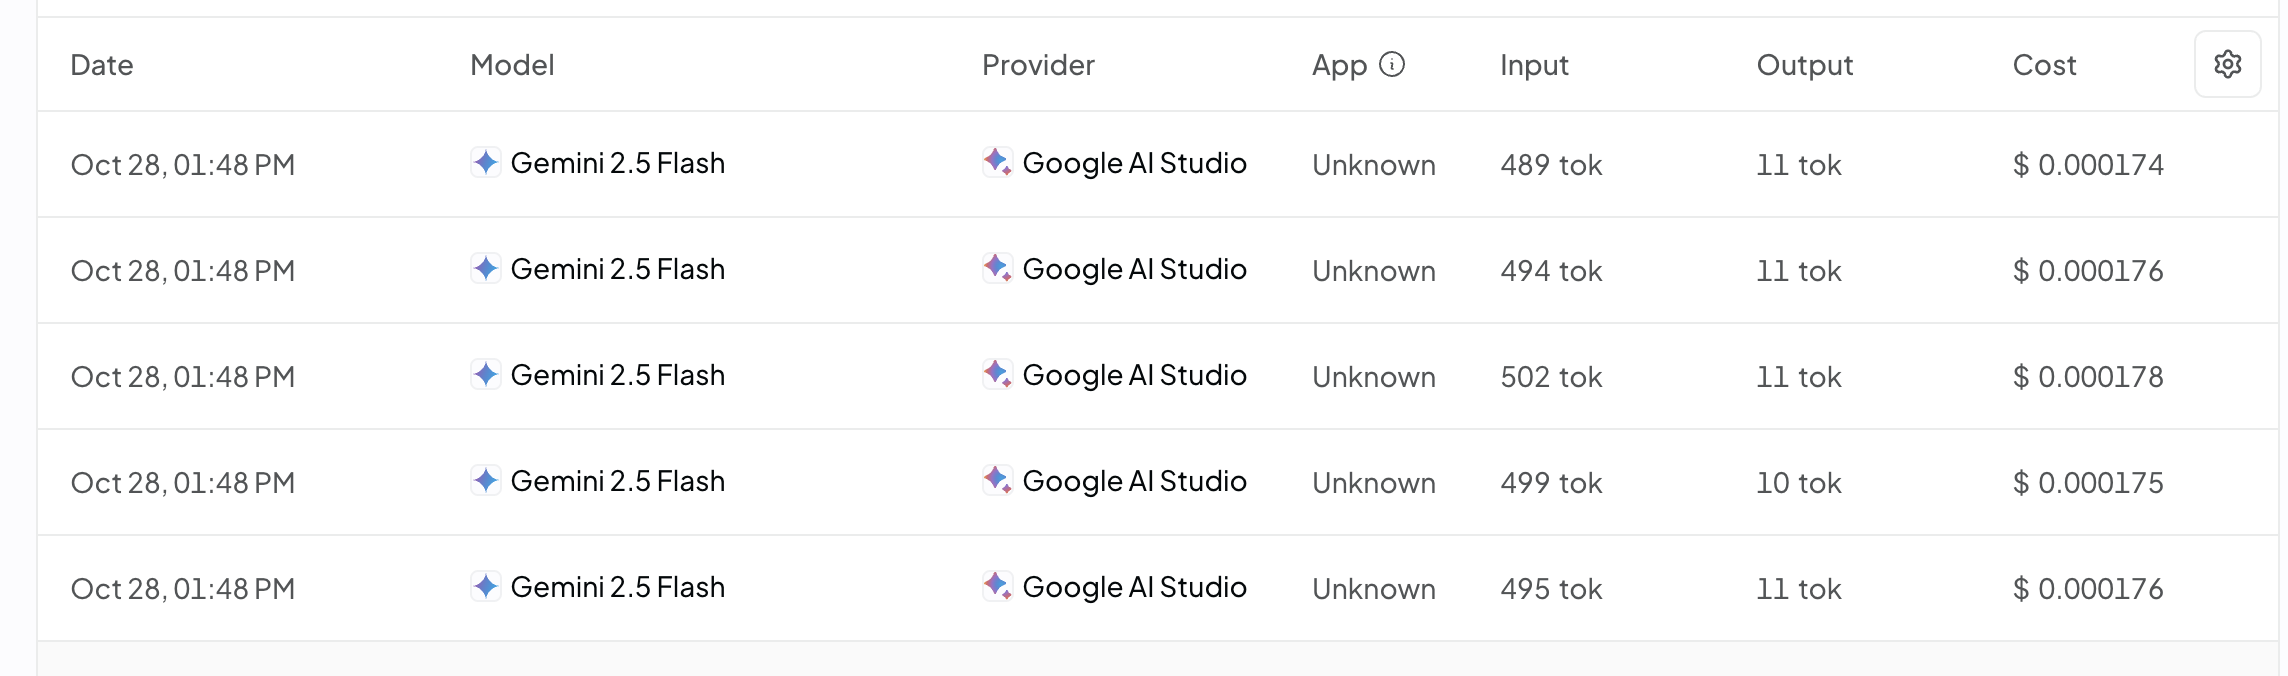

# Завдання 3: Заголовок + категорія оголошення

Скласти промпт, який генерує короткий заголовок (≤ 8 слів) і класифікує категорію з множини реліз | інцидент | рекомендація.

In [8]:
import os
import json
from openai import OpenAI
from google.colab import userdata

# Отримуємо ключ із захищеного сховища Colab
api_key = userdata.get('OPENROUTER_API_KEY')

client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=api_key
)
MODEL = "google/gemini-2.5-flash"

# 5 коротких текстів для аналізу
texts = [
    "Вийшла версія 2.0 з офлайн-режимом і новим дизайном.",
    "У частини користувачів не відкривається профіль після апдейту; працюємо над виправленням.",
    "Збираємо відгуки про новий модуль аналітики.",
    "На вихідних сервіс у режимі планового обслуговування.",
    "Рекомендуємо вмикати двофакторну автентифікацію."
]

# Промпт для генерації заголовка та визначення категорії
PROMPT_STUDENT = """
Ти — автоматична система формування коротких продуктових заголовків. Твоє завдання — згенерувати стислий, суцільний заголовок та визначити категорію сповіщення, і повернути результат строго у форматі JSON.

ПРАВИЛА ДЛЯ TITLE:
1. Іменниковий стиль: Заголовок має бути називною фразою. Заміняй дієслова на іменники (наприклад, замість "Збираємо..." -> "Збір...", замість "Не відкривається..." -> "Проблема з відкриттям..."). Для закликів до дії дозволено наказовий спосіб ("Увімкніть", "Заповніть").
2. ЗАБОРОНА двокрапок та ком: ЗАБОРОНЕНО використовувати двокрапку (:) та списки через коми в одному заголовку. Для зв'язку слів використовуй прийменники та сполучники ("з", "та", "і", "після").
3. Заборона вступних слів і префіксів: Не починай заголовок зі слів "Вийшла", "Рекомендуємо", "Повідомляємо", "Наразі" тощо, а також із назв категорій чи префіксів у будь-якій формі ("Рекомендація", "Інцидент", "Реліз", "Оголошення:", "Важливо:").
4. Обмеження довжини: СТРОГО до 8 слів включно (≤ 8 слів). Без зайвих "хвостів" у кінці.

ПРАВИЛА ДЛЯ CATEGORY:
Допустимі значення СТРОГО тільки з множини: "реліз", "інцидент", "рекомендація".
- "реліз": нові версії, оновлення, функціонал, режими роботи.
- "інцидент": збої, помилки, невідкриття сторінок, планове чи технічне обслуговування.
- "рекомендація": поради, прохання про відгуки, заклики до дій, безпека.

ПРИКЛАДИ ТРАНСФОРМАЦІЇ:
Вхід: "Представлено оновлення 4.0: нічний режим, покращений пошук."
Вихід: {"title":"Оновлення 4.0 з нічним режимом та покращеним пошуком","category":"реліз"}

Вхід: "Шукаємо тестувальників для перевірки нової платіжної системи."
Вихід: {"title":"Пошук тестувальників для нової платіжної системи","category":"рекомендація"}

Вхід: "Не працює авторизація через Google після збою на сервері."
Вихід: {"title":"Проблеми з авторизацією через Google","category":"інцидент"}

ФОРМАТ ВІДПОВІДІ:
Повертай ТІЛЬКИ JSON-об'єкт вигляду: {"title": "<заголовок>", "category": "<категорія>"}.
КАТЕГОРИЧНО ЗАБОРОНЕНО використовувати markdown-позначки (```json або ```).
"""

# Виклик моделі (мінімальний цикл)
for t in texts:
    resp = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "developer", "content": PROMPT_STUDENT.strip()},
            {"role": "user",
             "content": f"Проаналізуй текст і поверни ТІЛЬКИ JSON з ключами title та category.\nТекст: <<<<< {t} >>>>>"},
        ],
        temperature=0
    )
    result = resp.choices[0].message.content.strip()

    # Додаткове очищення на випадок, якщо модель все ж додасть markdown (запобіжник)
    if result.startswith("```json"):
        result = result[7:-3].strip()
    elif result.startswith("```"):
        result = result[3:-3].strip()

    try:
        json.loads(result) # перевірка, чи валідний JSON
        print(result)  # очікується чистий JSON без пояснень
    except json.JSONDecodeError:
        print(f"Помилка парсингу JSON. Відповідь моделі:\n{result}")

{"title":"Версія 2.0 з офлайн-режимом та новим дизайном","category":"реліз"}
{"title":"Проблема з відкриттям профілю після оновлення","category":"інцидент"}
{"title":"Збір відгуків про новий модуль аналітики","category":"рекомендація"}
{"title":"Планове обслуговування сервісу на вихідних","category":"інцидент"}
{"title":"Увімкніть двофакторну автентифікацію","category":"рекомендація"}


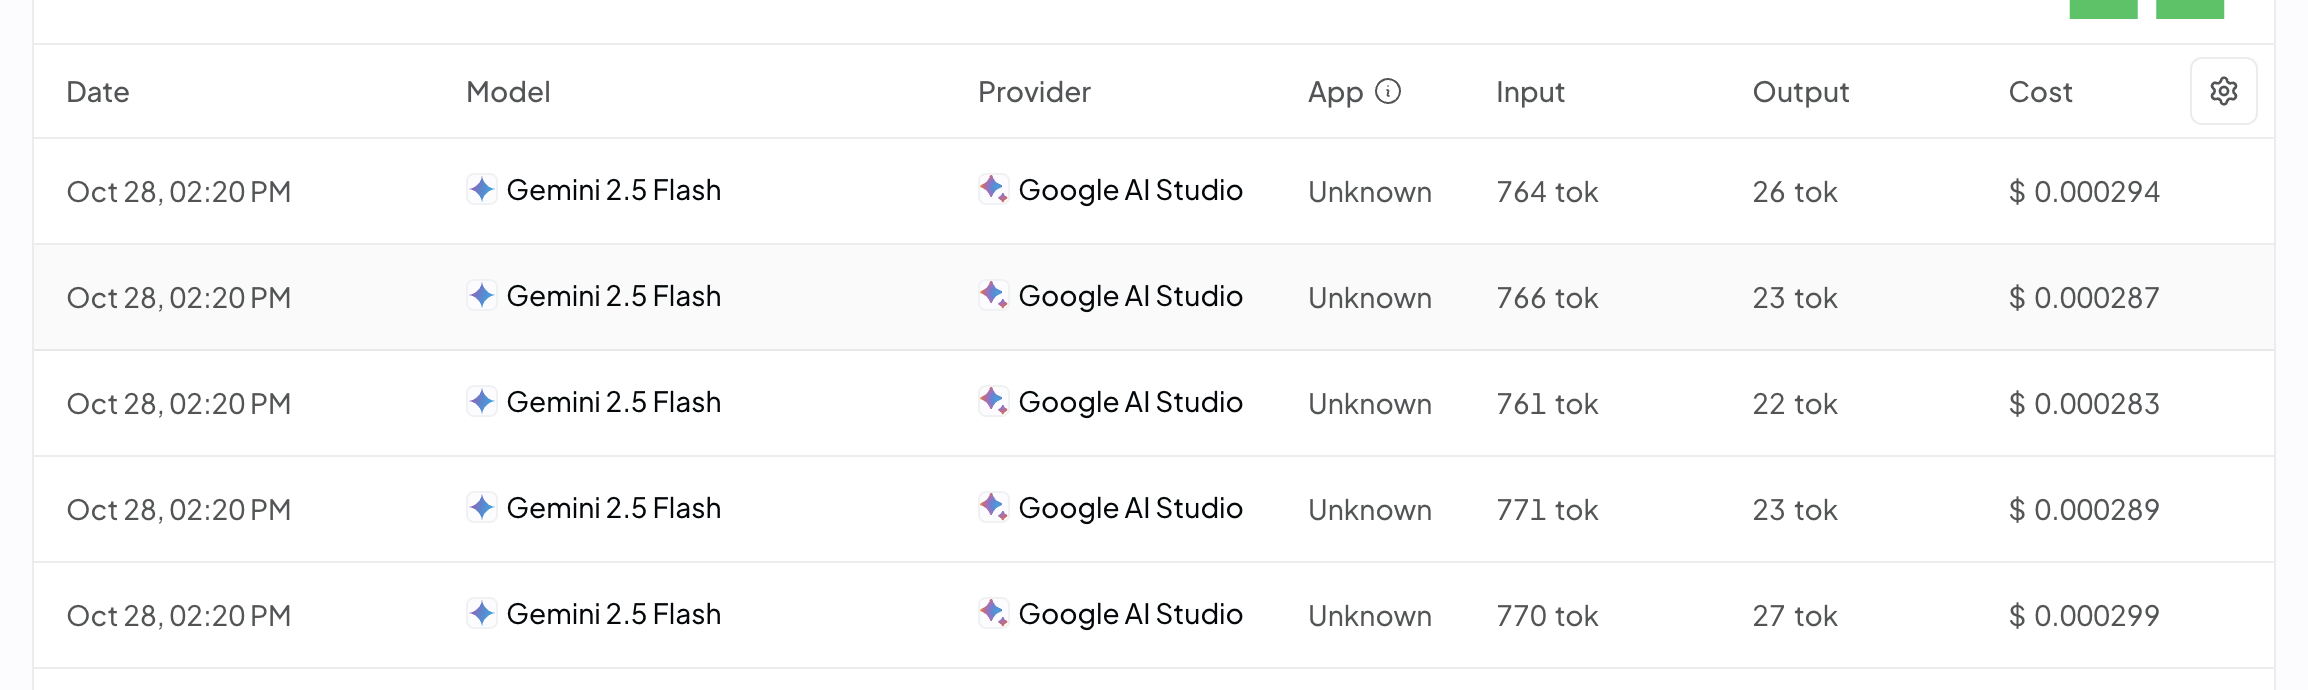